In [73]:
# ============================================
# LOAD DATA
# ============================================
!pip install ucimlrepo --quiet

from ucimlrepo import fetch_ucirepo
import pandas as pd

dataset = fetch_ucirepo(id=572)
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

# ---- FIX: strip whitespace from all column names ----
df.columns = df.columns.str.strip()

target_col = "Bankrupt?"

print("Shape:", df.shape)
print("Columns loaded successfully:", target_col in df.columns)

Shape: (6819, 96)
Columns loaded successfully: True


In [74]:
# ============================================
# WEEK 4 — Financial Layer Cleaning (Taiwan Bankruptcy Dataset)
# ============================================

import numpy as np

# ---- 0. Work on a copy, never touch the original ----
df_clean = df.copy()

In [75]:
# ---- 1. Define column groups from Week 3 findings ----

MINOR_OUTLIER_COLS = [
    "Revenue Per Share (Yuan ¥)", "Net Value Growth Rate", "Current Ratio",
    "Quick Ratio", "Total debt/Total net worth", "Accounts Receivable Turnover",
    "Average Collection Days", "Revenue per person", "Allocation rate per person",
    "Quick Assets/Current Liability", "Cash/Current Liability",
    "Inventory/Current Liability", "Long-term Liability to Current Assets",
    "Fixed Assets to Assets", "Total assets to GNP price"
]  # 15 features, <2% affected — cap at 99th percentile

BORDERLINE_COL = "Interest-bearing debt interest rate"  # 3.24% affected

SEVERE_COLS = [
    "Total Asset Growth Rate", "Cash Turnover Rate",
    "Research and development expense rate", "Inventory Turnover Rate (times)",
    "Quick Asset Turnover Rate", "Operating Expense Rate",
    "Current Asset Turnover Rate", "Fixed Assets Turnover Frequency"
]  # 8 features — drop entirely

MULTICOLLINEAR_PAIR = ["Current Liabilities/Equity", "Current Liability to Equity"]
# both r = 0.154 with target — keep one, drop the other
COL_TO_DROP_FROM_PAIR = "Current Liability to Equity"

print(f"Minor outlier cols: {len(MINOR_OUTLIER_COLS)}")
print(f"Borderline col: {BORDERLINE_COL}")
print(f"Severe cols to drop: {len(SEVERE_COLS)}")

Minor outlier cols: 15
Borderline col: Interest-bearing debt interest rate
Severe cols to drop: 8


In [76]:
# ---- Safety check: confirm every column name used anywhere in this pipeline exists ----
ENGINEERED_FEATURE_INPUTS = [
    "Net worth/Assets", "Debt ratio %",
    "ROA(A) before interest and % after tax",
    "ROA(B) before interest and depreciation after tax",
    "ROA(C) before interest and depreciation before interest",
    "Current Liability to Assets", "Borrowing dependency"
]

all_expected_cols = (
    MINOR_OUTLIER_COLS + [BORDERLINE_COL] + SEVERE_COLS
    + MULTICOLLINEAR_PAIR + ENGINEERED_FEATURE_INPUTS
)
missing_cols = [col for col in all_expected_cols if col not in df_clean.columns]

if missing_cols:
    print("⚠️ These columns were NOT found in the dataframe:")
    for col in missing_cols:
        print(f"  - '{col}'")
else:
    print("✅ All expected columns found — safe to proceed.")

✅ All expected columns found — safe to proceed.


In [77]:
# ---- 2. Reusable function: fit cap thresholds (call this on TRAIN only) ----
def fit_cap_thresholds(df, columns, upper_quantile=0.99):
    """Learn the capping threshold for each column from training data only."""
    thresholds = {}
    for col in columns:
        thresholds[col] = df[col].quantile(upper_quantile)
    return thresholds


def apply_caps(df, thresholds):
    """Apply pre-fitted cap thresholds to any dataframe (train or test)."""
    df = df.copy()
    for col, cap_value in thresholds.items():
        df[col] = df[col].clip(upper=cap_value)
    return df

In [78]:
# ---- 3. Borderline feature decision: cap it the same way as the minor group ----
# Rationale: 3.24% affected is much closer to the <2% minor tier's behavior
# than the 18-88% severe tier — capping preserves the feature instead of
# losing a potentially useful predictor over a small number of bad rows.
cols_to_cap = MINOR_OUTLIER_COLS + [BORDERLINE_COL]
print(f"Total columns to cap: {len(cols_to_cap)}")

Total columns to cap: 16


In [79]:
# ---- 4. Reusable function: drop severe + multicollinear columns ----
def drop_unreliable_columns(df, severe_cols, col_to_drop_from_pair):
    """Drop severely corrupted features and resolve multicollinearity."""
    cols_to_drop = severe_cols + [col_to_drop_from_pair]
    return df.drop(columns=cols_to_drop, errors="ignore")

In [80]:
# ---- 5. Reusable function: feature engineering ----
def engineer_financial_features(df):
    """
    Create new features from existing financial ratios.
    Each feature has a one-sentence business rationale (see comments).
    """
    df = df.copy()

    # Liquidity Buffer: net equity cushion relative to debt burden.
    # Higher value = more equity buffer to absorb losses before insolvency.
    df["Liquidity_Buffer"] = df["Net worth/Assets"] - df["Debt ratio %"]

    # Profitability Composite: averages the three ROA variants into one
    # signal, reducing noise from any single ROA calculation method.
    df["Profitability_Composite"] = df[
        ["ROA(A) before interest and % after tax",
         "ROA(B) before interest and depreciation after tax",
         "ROA(C) before interest and depreciation before interest"]
    ].mean(axis=1)

    # Compounding Leverage Risk: captures firms that are simultaneously
    # burdened by short-term liabilities AND reliant on borrowing —
    # each factor alone may look moderate, but together they compound risk.
    df["Compounding_Leverage_Risk"] = (
        df["Current Liability to Assets"] * df["Borrowing dependency"]
    )

    return df

In [81]:
# ---- 6. Master function — combines everything, reusable on train/test ----
def clean_financial_layer(df, cap_thresholds=None, is_training=False):
    """
    Full Week 4 cleaning pipeline for the financial layer.

    - If is_training=True: fits cap thresholds on this data and returns
      (cleaned_df, fitted_thresholds) — call this on the TRAIN set.
    - If is_training=False: requires cap_thresholds from training,
      applies them without re-fitting — call this on the TEST set.
    """
    df = df.copy()

    if is_training:
        cap_thresholds = fit_cap_thresholds(df, cols_to_cap, upper_quantile=0.99)

    df = apply_caps(df, cap_thresholds)
    df = drop_unreliable_columns(df, SEVERE_COLS, COL_TO_DROP_FROM_PAIR)
    df = engineer_financial_features(df)

    if is_training:
        return df, cap_thresholds
    return df

In [82]:
# ---- 7. Run it (example — replace with your actual train/test split) ----
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_clean, test_size=0.2, stratify=df_clean[target_col], random_state=42
)

train_cleaned, fitted_thresholds = clean_financial_layer(train_df, is_training=True)
test_cleaned = clean_financial_layer(test_df, cap_thresholds=fitted_thresholds, is_training=False)

print("Train shape after cleaning:", train_cleaned.shape)
print("Test shape after cleaning:", test_cleaned.shape)
print("Final feature count:", train_cleaned.shape[1] - 1, "(excluding target)")

Train shape after cleaning: (5455, 90)
Test shape after cleaning: (1364, 90)
Final feature count: 89 (excluding target)


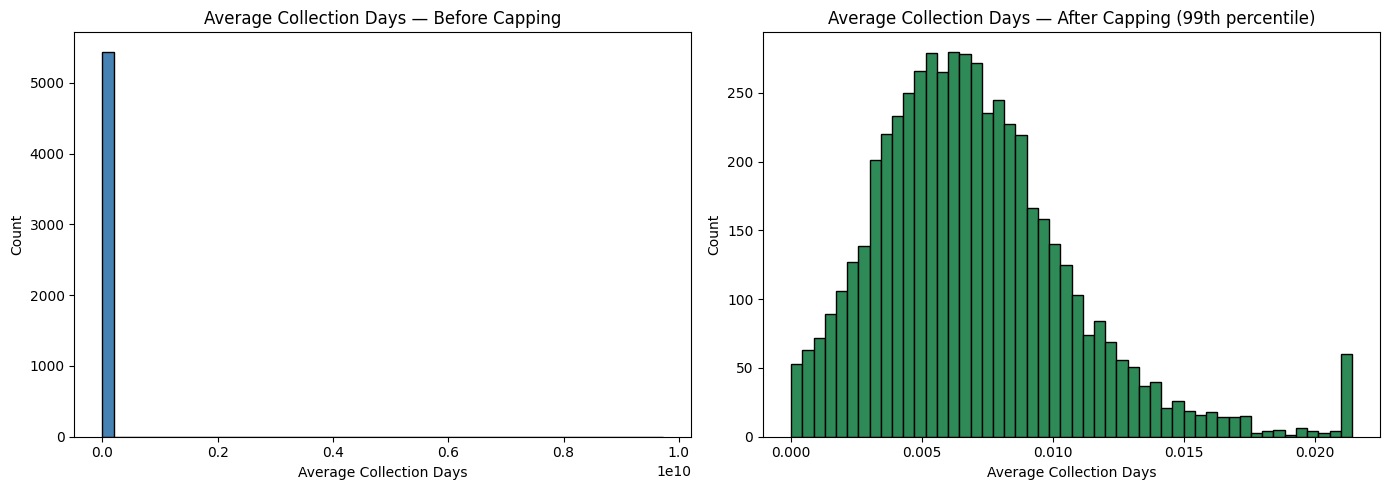

Before capping — min: 0.000, max: 9730000000.000
After capping  — min: 0.000, max: 0.021
Cap threshold used (99th percentile): 0.021


In [85]:
# ============================================
# (1) BEFORE/AFTER HISTOGRAM — capping effect on one example feature
# ============================================
import matplotlib.pyplot as plt

# Pick one capped feature to visualize — "Average Collection Days" is a good example
# since it's easy to interpret and was part of the minor-outlier tier
example_col = "Average Collection Days"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BEFORE: raw train data, pre-capping
axes[0].hist(train_df[example_col], bins=50, color="steelblue", edgecolor="black")
axes[0].set_title(f"{example_col} — Before Capping")
axes[0].set_xlabel(example_col)
axes[0].set_ylabel("Count")

# AFTER: cleaned train data, post-capping
axes[1].hist(train_cleaned[example_col], bins=50, color="seagreen", edgecolor="black")
axes[1].set_title(f"{example_col} — After Capping (99th percentile)")
axes[1].set_xlabel(example_col)
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

# Print the actual before/after range for the write-up
print(f"Before capping — min: {train_df[example_col].min():.3f}, max: {train_df[example_col].max():.3f}")
print(f"After capping  — min: {train_cleaned[example_col].min():.3f}, max: {train_cleaned[example_col].max():.3f}")
print(f"Cap threshold used (99th percentile): {fitted_thresholds[example_col]:.3f}")

In [84]:
# ============================================
# (2) NaN CHECK — confirm no missing values introduced during cleaning
# ============================================
train_nan_count = train_cleaned.isnull().sum().sum()
test_nan_count = test_cleaned.isnull().sum().sum()

print("Any NaN in train?", train_nan_count)
print("Any NaN in test?", test_nan_count)

# If anything unexpected shows up, this breaks it down by column
if train_nan_count > 0:
    print("\nColumns with NaN in train:")
    print(train_cleaned.isnull().sum()[train_cleaned.isnull().sum() > 0])

if test_nan_count > 0:
    print("\nColumns with NaN in test:")
    print(test_cleaned.isnull().sum()[test_cleaned.isnull().sum() > 0])

Any NaN in train? 0
Any NaN in test? 0
